# Keypoint detectors: visual check
Plots the keypoints of one image for all the detectors in one figure.

In [18]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent))

from keypoints import detect, anms
from segmentation import resize_max_side

In [19]:
PROJECT_ROOT = Path.cwd().parent.parent
DATA_DIR = PROJECT_ROOT / "data"
BBDD = DATA_DIR / "BBDD"

In [20]:
METHODS = ["dog", "harris_laplace", "hessian_laplace", "fast"]
MAX_KPS = 500
CLAHE = False
N_SHOW = 100

PARAMS = {
    "dog": {
        "contrast": 0.04,
        "edge": 10,
        "sigma": 1.6,
    },
    "harris_laplace": {
        "n_scales": 8,
        "sigma0": 1.6,
        "k": 1.4,
        "harris_thr": 1e-6,
        "log_thr": 0.01,
        "alpha": 0.04,
    },
    "hessian_laplace": {
        "n_scales": 8,
        "sigma0": 1.6,
        "k": 1.4,
        "det_thr": 2e-4,
        "log_thr": 0.01,
        "edge": 10,
    },
    "fast": {
        "thr": 20,
        "n_levels": 4,
        "ratio": 1.5,
        "sigma0": 2.0,
    }
}

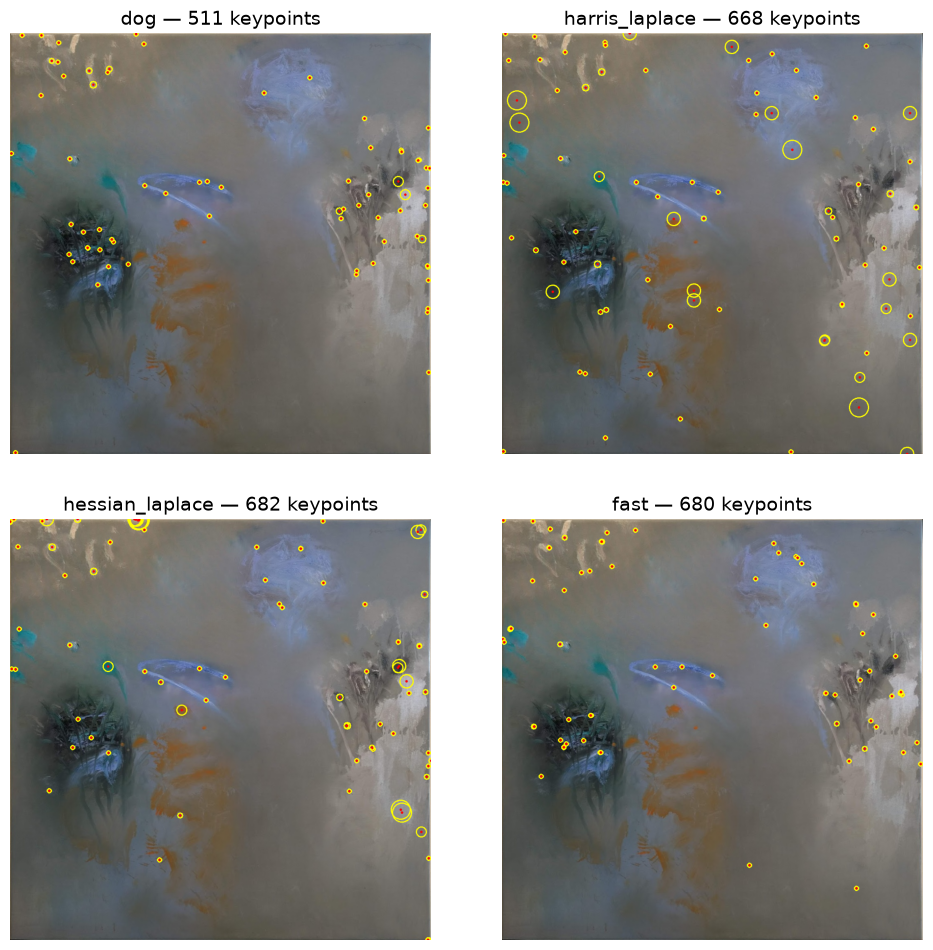

In [23]:
img = resize_max_side(cv2.imread(str(BBDD / "bbdd_00006.jpg")))

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
for ax, method in zip(axes.ravel(), METHODS):
    keypoints = detect(img, method=method, max_kps=MAX_KPS, clahe=CLAHE, **PARAMS[method])

    image_with_keypoints = img.copy()
    for kp in anms(keypoints, N_SHOW):
        x, y = map(int, kp.pt)
        radius = max(5, int(kp.size / 2))
        cv2.circle(image_with_keypoints, (x, y), radius, (0, 255, 255), 2)
        cv2.circle(image_with_keypoints, (x, y), 3, (0, 0, 255), -1)

    ax.imshow(cv2.cvtColor(image_with_keypoints, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{method} — {len(keypoints)} keypoints", fontsize=14)
    ax.axis("off")

plt.tight_layout(h_pad=3, rect=(0, 0, 1, 0.96))
plt.show()

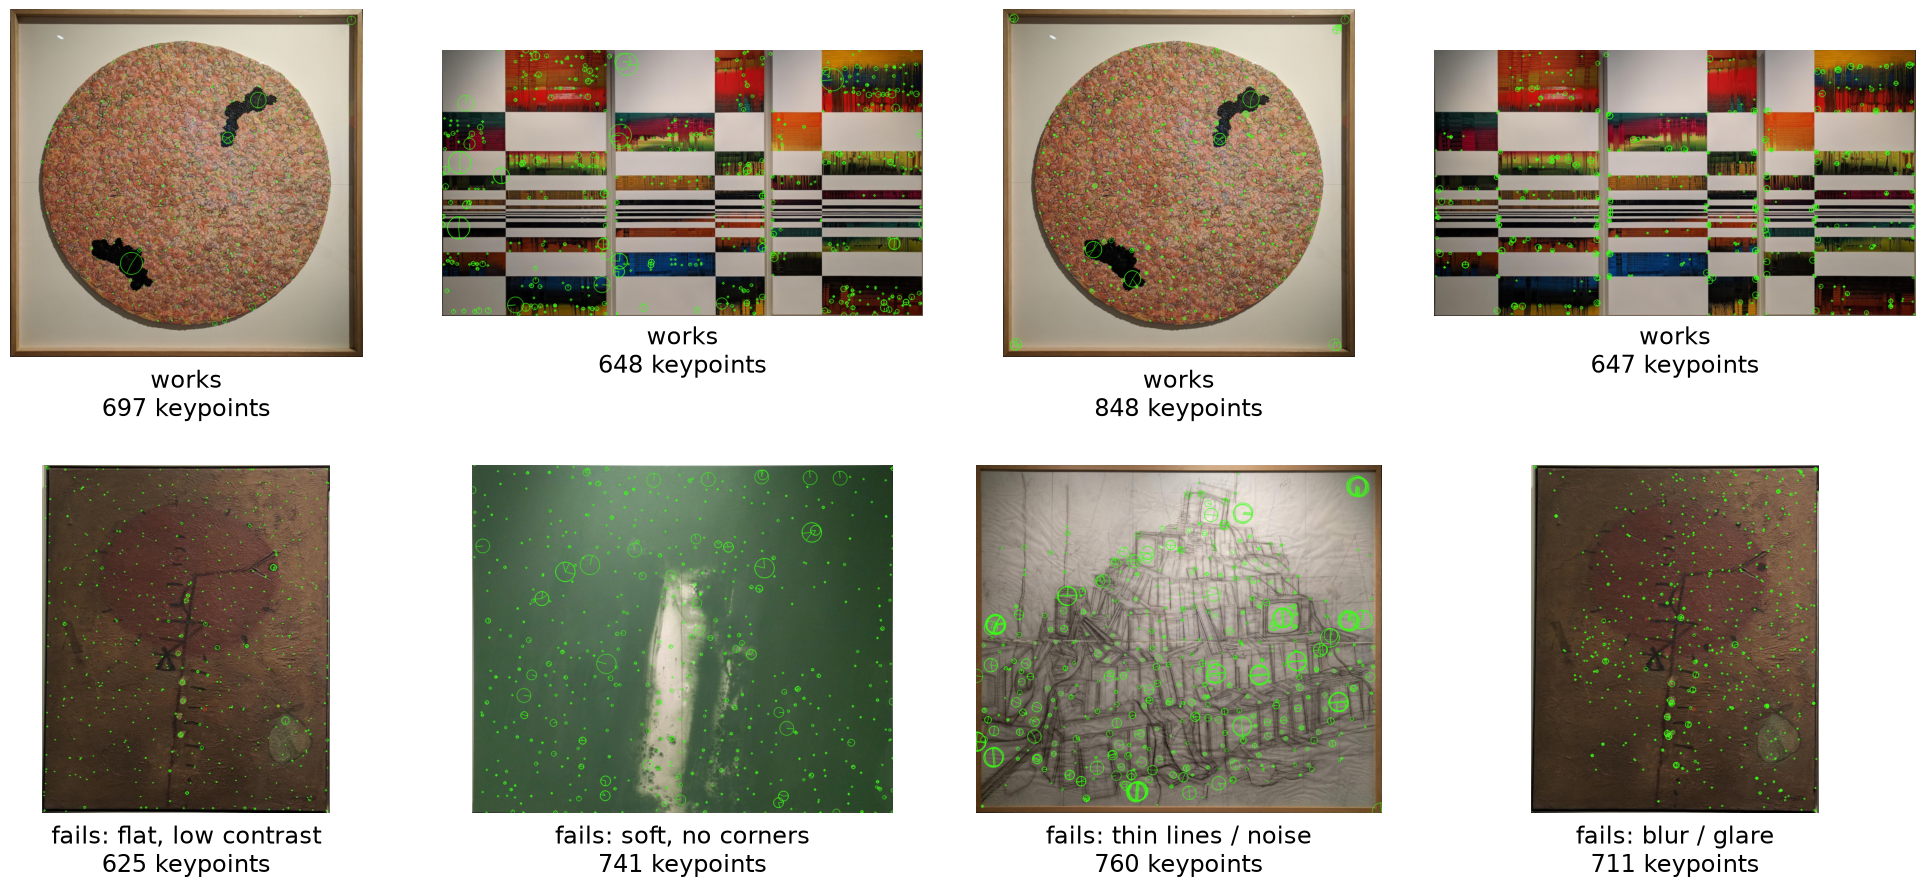

In [25]:
PICKS = {
    "dog":             ("bbdd_00042.jpg", "bbdd_00092.jpg", "flat, low contrast"),
    "harris_laplace":  ("bbdd_00000.jpg",  "bbdd_00124.jpg",  "soft, no corners"),
    "hessian_laplace": ("bbdd_00042.jpg", "bbdd_00106.jpg", "thin lines / noise"),
    "fast":            ("bbdd_00000.jpg", "bbdd_00092.jpg", "blur / glare"),
}
MAX_KPS = 500
NEON_GREEN_BGR = (20, 255, 57)

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for j, (m, (good, bad, why)) in enumerate(PICKS.items()):
    for i, (path, label) in enumerate(((good, "works"), (bad, f"fails: {why}"))):
        img = resize_max_side(cv2.imread(str(BBDD / path)))
        kps = detect(img, m, max_kps=MAX_KPS)
        vis = cv2.drawKeypoints(img, kps, None, color=NEON_GREEN_BGR,
                                flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
        ax = axes[i, j]
        ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
        ax.text(0.5, -0.03, f"{label}\n{len(kps)} keypoints", transform=ax.transAxes,
                ha="center", va="top", fontsize=17)
        ax.axis("off")
plt.tight_layout(h_pad=3)
plt.show()